# How much do the settings matter?

Every run of pylovo stores its grids under a version (`VERSION_ID`) together with a snapshot of all generation
settings. Changing one setting and generating again under a new version shows its effect. This notebook compares the
Bavaria run (version `1`) with four variants of the three example areas, each with one setting changed:

| Version | Setting |
| --- | --- |
| `tut-osm` | existing station positions from open data (OSM, LoD2) are used first |
| `tut-reach` | a new station may supply buildings up to 1500 m away instead of 1000 m |
| `tut-cabin` | houses are connected through cable cabinets instead of tee joints |
| `tut-large` | stations one rating step larger (rural 400/630 kVA, otherwise 630/800 kVA) |

**Needs:** the `notebooks` extra (`uv sync --extra notebooks`). With a database in your `.env` the notebook reads the grids from it, otherwise from the example data that ship with pylovo (`data/examples`: three Bavarian postcode areas). The variants are part of the example data; a database without them falls back to it.

In [1]:
plz = 85256                       # the maps (the key figures cover all three example areas)
versions = ["1", "tut-osm", "tut-reach", "tut-cabin", "tut-large"]

In [2]:
from functools import reduce

import matplotlib.pyplot as plt
import pandas as pd

from pylovo.examples import EXAMPLE_AREAS, TutorialData
from pylovo.plotting import lv_grid, style
from pylovo.version_snapshot import compare_snapshots

style.apply_style(dpi=150)
data = {version: TutorialData(plz, version) for version in versions}
for tutorial_data in data.values():
    print(tutorial_data)

TutorialData(plz=85256, version 1, from the example data: no database configured)
TutorialData(plz=85256, version tut-osm, from the example data: no database configured)
TutorialData(plz=85256, version tut-reach, from the example data: no database configured)
TutorialData(plz=85256, version tut-cabin, from the example data: no database configured)
TutorialData(plz=85256, version tut-large, from the example data: no database configured)


## 1 What differs between the versions

The stored snapshots tell exactly which settings differ from version `1`.

In [3]:
def value(parameters, path):
    return reduce(lambda node, key: node[key], path.split("."), parameters)

base = data[versions[0]].parameters
rows = []
for version in versions[1:]:
    changed, _ = compare_snapshots(base, data[version].parameters)
    rows += [(version, path, value(base, path), value(data[version].parameters, path)) for path in changed]
pd.DataFrame(rows, columns=["version", "setting", f"version {versions[0]}", "variant"]).set_index("version")

,setting,version 1,variant
version,,,
tut-osm,transformer_placement.use_open_transformer_pos...,False,True
tut-reach,transformer_placement.max_greenfield_trafo_dis...,1000,1500
tut-cabin,cable_dimensioning.house_connection,joint,cabinet
tut-large,transformer_placement.transformer_mapping.1,"[250, 400]","[400, 630]"
tut-large,transformer_placement.transformer_mapping.2,"[400, 630]","[630, 800]"
tut-large,transformer_placement.transformer_mapping.3,"[400, 630]","[630, 800]"


## 2 The grids of each version

The same area and the same buildings; each colour is one grid. Grids with a voltage violation are listed below.

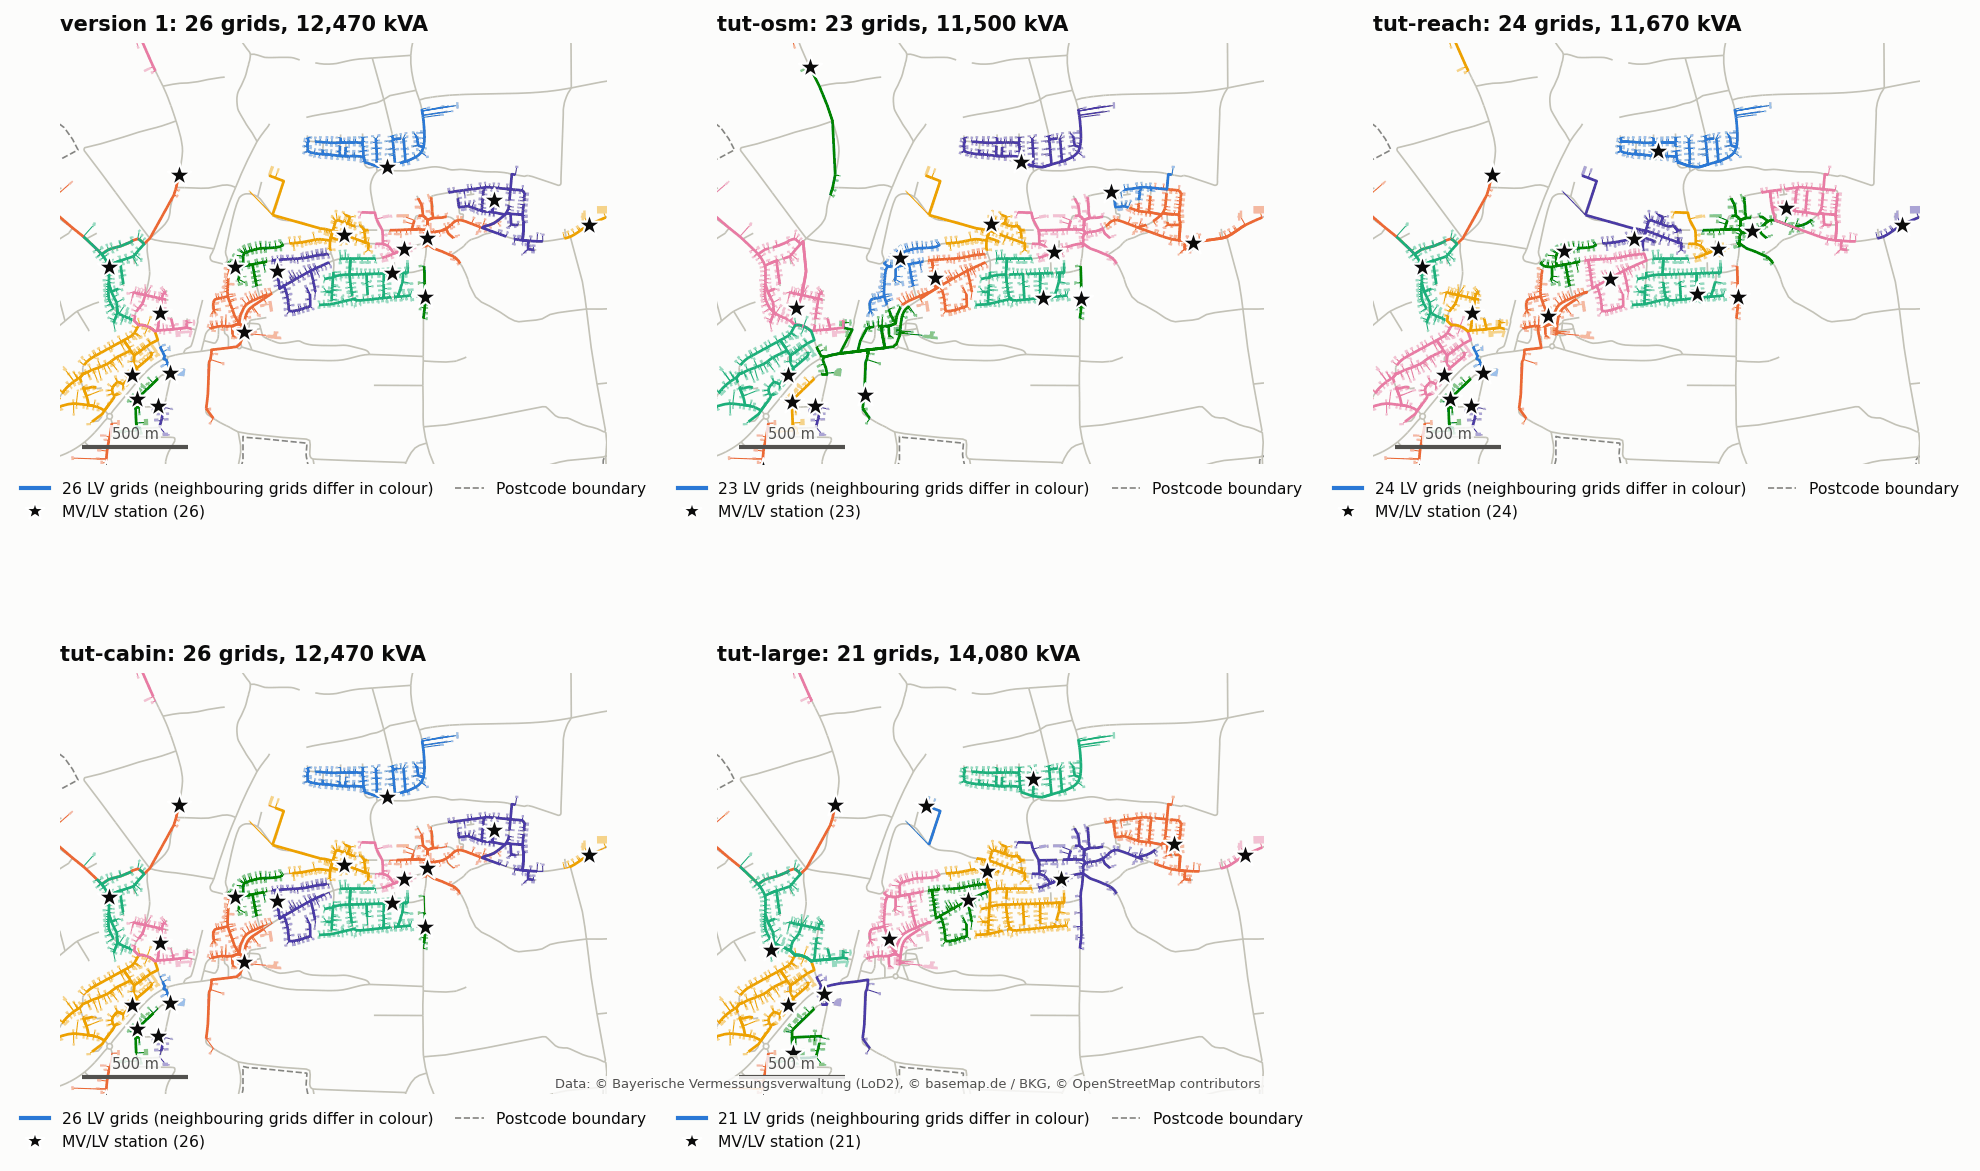

In [4]:
bounds = lv_grid.core_bounds(data[versions[0]].layers)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, version in zip(axes.flat, versions):
    grids = data[version].grids
    name = "version 1" if version == "1" else version
    ax_title = f"{name}: {len(grids)} grids, {int(grids['transformer_rated_power'].sum()):,} kVA"
    lv_grid.plot_lv_overview(data[version].layers, extent=bounds, ax=ax, title=ax_title, labels=False,
                             attribution="" if version != versions[-1] else None)
axes.flat[-1].set_visible(False)

- **tut-osm** keeps the stations that exist in OpenStreetMap and the LoD2 data, and adds new ones only where they
  do not reach.
- **tut-reach** lets new stations reach further, so fewer grids with longer feeders.
- **tut-cabin** keeps the same stations; only the house connections change (section 4).
- **tut-large** allows larger stations, so fewer of them.

## 3 Effect on the key figures

The same comparison for all three example areas.

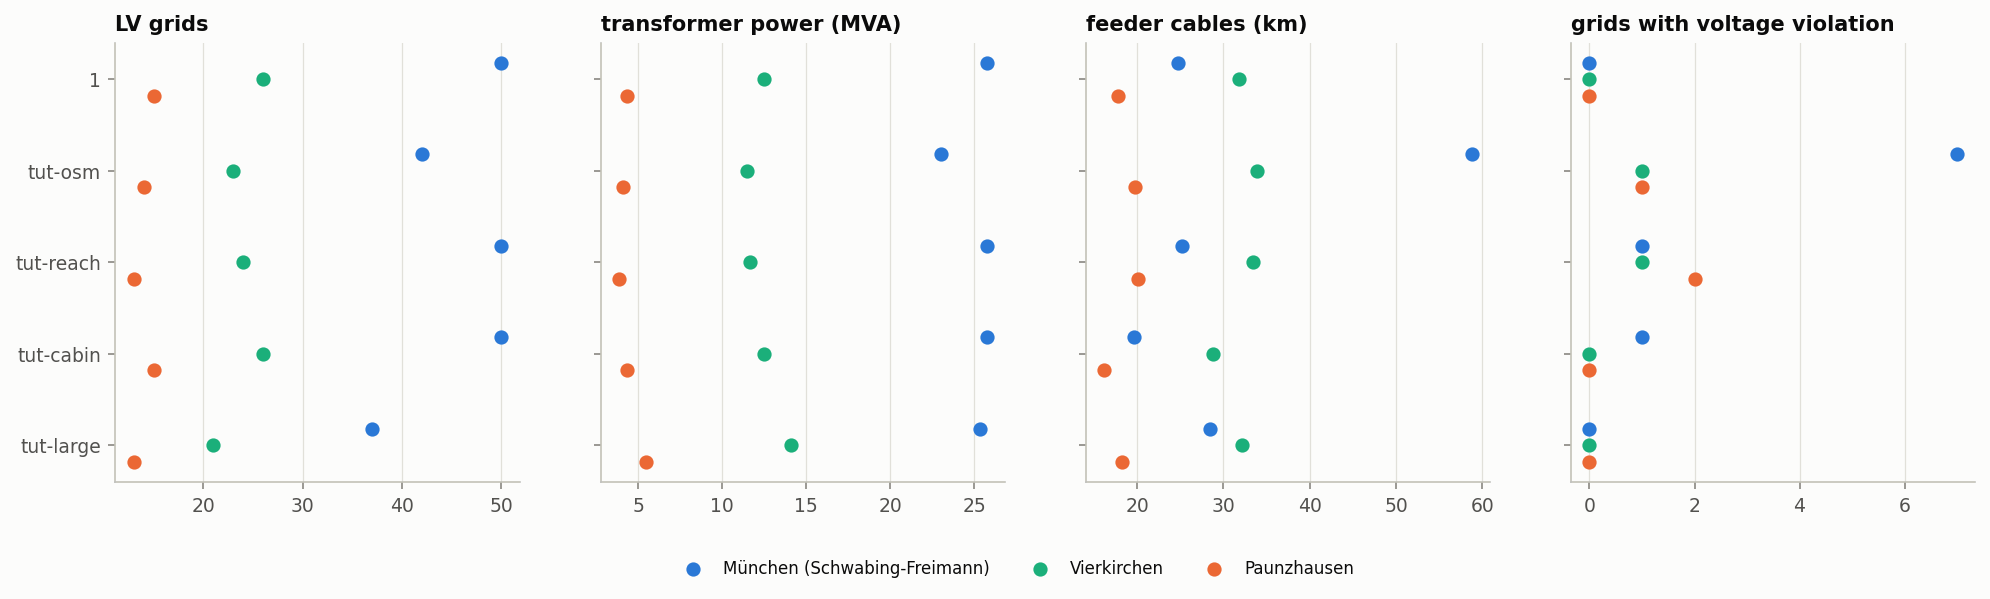

In [5]:
rows = []
for area in EXAMPLE_AREAS:
    for version in versions:
        grids = TutorialData(area, version).summary()
        rows.append({"area": EXAMPLE_AREAS[area]["name"], "version": version, "LV grids": len(grids),
                     "transformer power (MVA)": grids["transformer_rated_power"].sum() / 1000,
                     "feeder cables (km)": grids["feeder_km"].sum(),
                     "grids with voltage violation": int((grids["power_flow_status"] != "converged").sum())})
table = pd.DataFrame(rows)

figures = ["LV grids", "transformer power (MVA)", "feeder cables (km)", "grids with voltage violation"]
names = list(dict.fromkeys(table["area"]))
colors = style.categorical_colors(names)
fig, axes = plt.subplots(1, len(figures), figsize=(16, 3.8), sharey=True)
for ax, figure in zip(axes, figures):
    for offset, area in zip((-0.18, 0.0, 0.18), names):       # the areas side by side in each row
        rows_of_area = table[table["area"] == area]
        rows = [versions.index(version) + offset for version in rows_of_area["version"]]
        ax.scatter(rows_of_area[figure], rows, color=colors[area], s=34, label=area, zorder=3)
    ax.set_title(figure, loc="left")
    style.tidy_value_axes(ax, "x")
axes[0].set_yticks(range(len(versions)), versions)
axes[0].invert_yaxis()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False);

- **Existing stations (tut-osm)** change the city most. The mapped stations are not always where the load is, so
  the feeders get much longer and several grids break the voltage limit.
- **A longer reach (tut-reach)** hardly changes the city, where the station capacity limits the grids, but merges
  grids in the suburb and the village. Some of their longer feeders break the limit.
- **Cable cabinets (tut-cabin)** keep the stations. Part of each feeder route becomes house-connection cable, so the
  feeder length falls.
- **Larger stations (tut-large)** mean fewer grids in all three areas, a quarter fewer in the city.

## 4 Cable cabinets instead of tee joints

With `HOUSE_CONNECTION: cabinet`, houses are connected to cable cabinets along the feeder instead of tee joints at
the nearest point. The stations stay the same, the cabling changes.

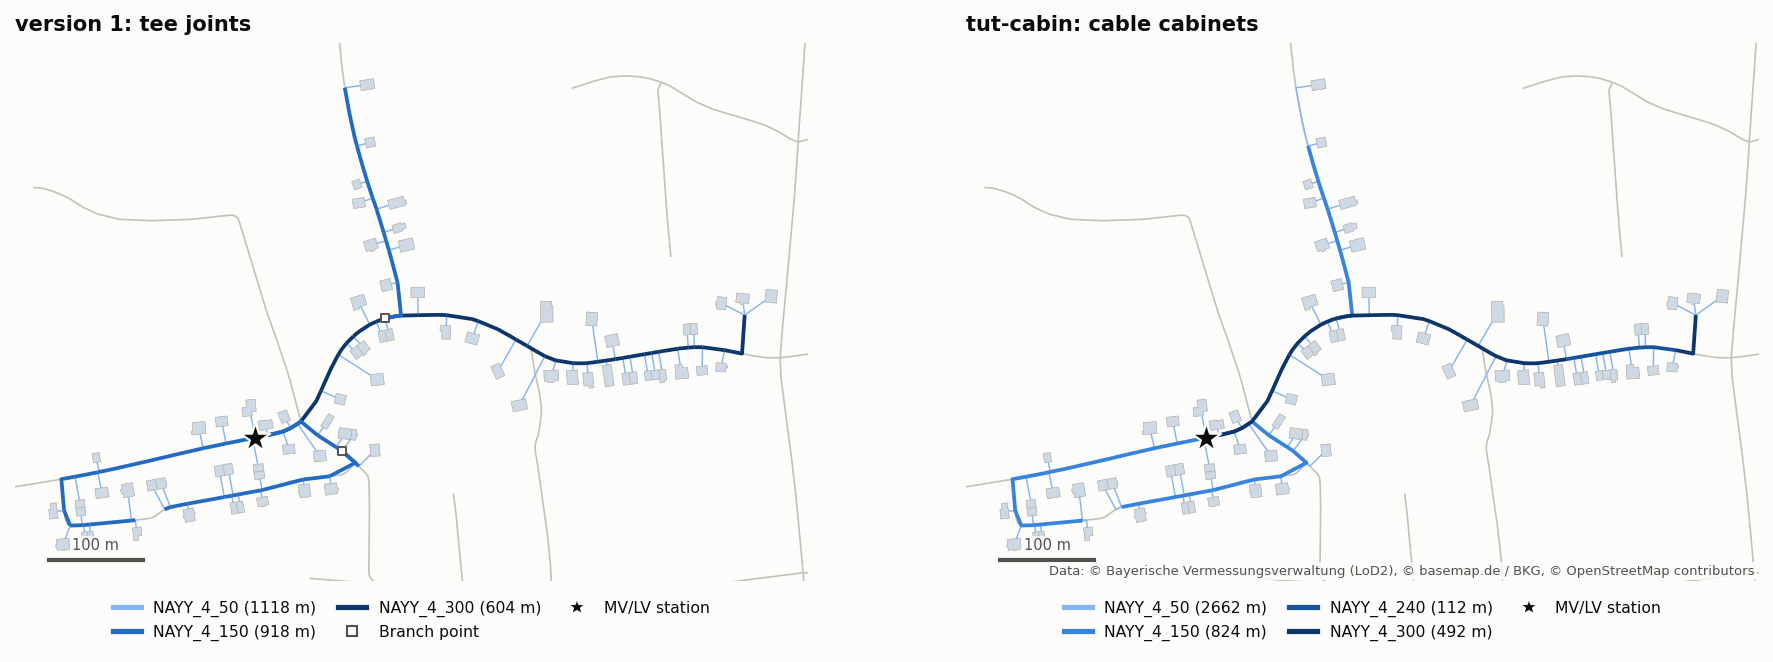

In [6]:
kcid, bcid = data[versions[0]].typical_grid
fig, axes = plt.subplots(1, 2, figsize=(15, 6.4))
lv_grid.plot_lv_grid(data["1"].layers, kcid, bcid, buildings=None, ax=axes[0], title="version 1: tee joints",
                     attribution="")
lv_grid.plot_lv_grid(data["tut-cabin"].layers, kcid, bcid, buildings=None, ax=axes[1],
                     title="tut-cabin: cable cabinets");

## 5 Make your own version

1. Copy `config/config_generation_lv.yaml` into a folder `config/` of a new working directory and change
   `VERSION_ID`, `VERSION_COMMENT` and the setting.
2. Run `uv run pylovo-generate --plz 85256` in that directory: pylovo reads `config/` of the working directory
   first ([configuration](https://pylovo.readthedocs.io/en/latest/user_guide/configuration.html)).
3. Compare with `TutorialData(85256, version_id="your-id")` as above.

The variants of this notebook were made that way with `docs/scripts/make_tutorial_versions.py`.